In [1]:

from google.colab import files
import zipfile

uploaded = files.upload()
zip_file = next(iter(uploaded))

with zipfile.ZipFile(zip_file, "r") as z:
    z.extractall("data")

    print("Dataset extracted successfully!")


Saving Financial analysis_Data Set.xlsx to Financial analysis_Data Set (1).xlsx
Dataset extracted successfully!


In [10]:
import pandas as pd
df = pd.read_excel("Financial analysis_Data Set.xlsx")
print(df.shape)
print(df.columns)
df.head()

(24, 8)
Index(['Month', 'Development Costs', 'Operatinal Costs', 'Marketing Costs',
       'Travelling Cost', 'Training Cost', 'Maintenance Cost', 'Expenses'],
      dtype='object')


,Month,Development Costs,Operatinal Costs,Marketing Costs,Travelling Cost,Training Cost,Maintenance Cost,Expenses
0,2023-01-01,107000,12000,10000,4000,6000,4000,Budget
1,2023-02-01,107000,12000,5000,4000,6000,4000,Budget
2,2023-03-01,108000,12000,5000,4000,6000,4000,Budget
3,2023-04-01,107000,12000,10000,4000,6000,4000,Budget
4,2023-05-01,111100,12000,4000,4000,6000,4000,Budget


In [11]:
print(df["Expenses"].value_counts())

Expenses
Budget    12
Actual    12
Name: count, dtype: int64


In [12]:
budget = df[df["Expenses"] == "Budget"].set_index("Month")
actual = df[df["Expenses"] == "Actual"].set_index("Month")

print("Budget data:", budget.shape)
print("Actual data:", actual.shape)

Budget data: (12, 7)
Actual data: (12, 7)


In [13]:
variance = actual.iloc[:, :-1] - budget.iloc[:, :-1]

print(variance.head())

            Development Costs  Operatinal Costs  Marketing Costs  \
Month                                                              
2023-01-01                -50              3600             -180   
2023-02-01               2000              -302            -1444   
2023-03-01                500              1453             1800   
2023-04-01               2900              3790             1400   
2023-05-01                660              -492            -1100   

            Travelling Cost  Training Cost  Maintenance Cost  
Month                                                         
2023-01-01             -800           -500              -800  
2023-02-01            -1700            500             -1200  
2023-03-01             1300          -6000              3800  
2023-04-01            -1800          -2000              1700  
2023-05-01            -2800              0               600  


In [14]:
print(variance.sum().sort_values(ascending=False))

Operatinal Costs      9082
Maintenance Cost      2487
Marketing Costs      -5324
Travelling Cost      -6700
Training Cost       -18000
Development Costs   -25565
dtype: int64


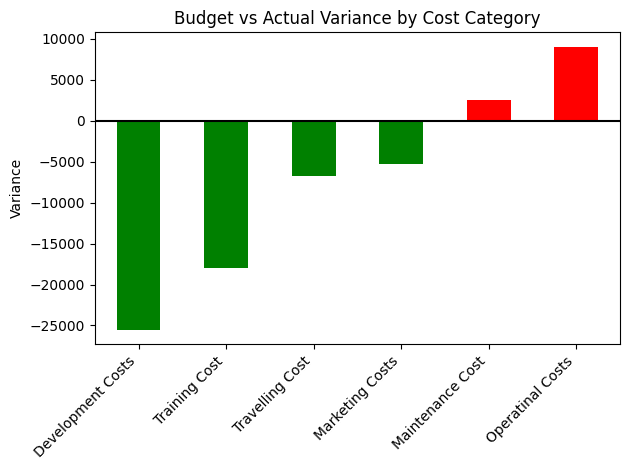

In [15]:
# Visualization
import matplotlib.pyplot as plt

v = variance.sum().sort_values()
colors = ["green" if x < 0 else "red" for x in v]

v.plot(kind="bar", color=colors)
plt.title("Budget vs Actual Variance by Cost Category")
plt.ylabel("Variance")
plt.axhline(0, color="black")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

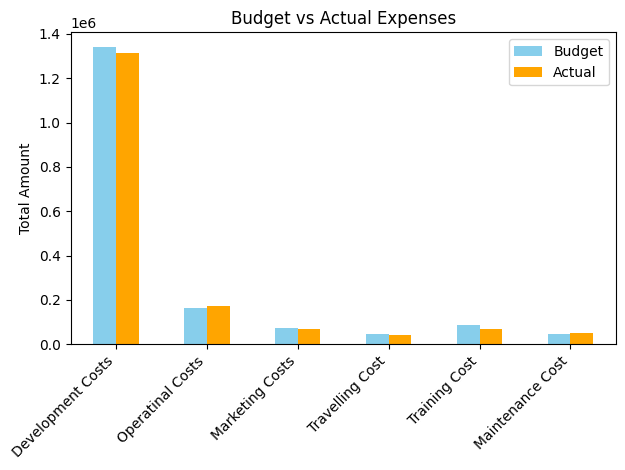

In [16]:
import matplotlib.pyplot as plt

budget_total = budget.iloc[:, :-1].sum()
actual_total = actual.iloc[:, :-1].sum()

comparison = pd.DataFrame({
    "Budget": budget_total,
        "Actual": actual_total
        })

comparison.plot(kind="bar", color=["skyblue", "orange"])

plt.title("Budget vs Actual Expenses")
plt.ylabel("Total Amount")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
total_budget = budget.iloc[:, :-1].sum().sum()
total_actual = actual.iloc[:, :-1].sum().sum()

execution_rate = (total_actual / total_budget) * 100

print("Total Budget:", total_budget)
print("Total Actual Expenses:", total_actual)
print("Budget Execution Rate:", round(execution_rate, 2), "%")

Total Budget: 1762200
Total Actual Expenses: 1718180
Budget Execution Rate: 97.5 %


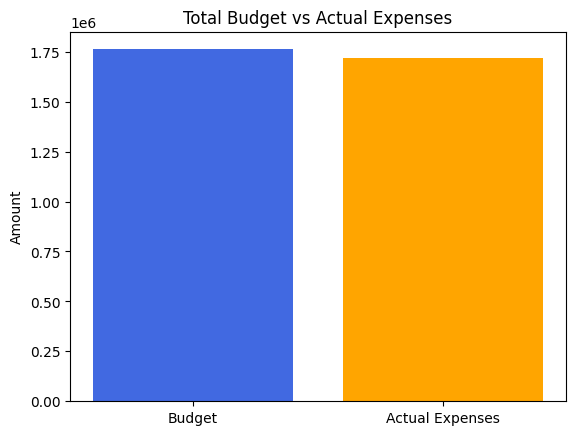

In [18]:
values = [total_budget, total_actual]
labels = ["Budget", "Actual Expenses"]

plt.bar(labels, values, color=["royalblue", "orange"])
plt.title("Total Budget vs Actual Expenses")
plt.ylabel("Amount")
plt.show()

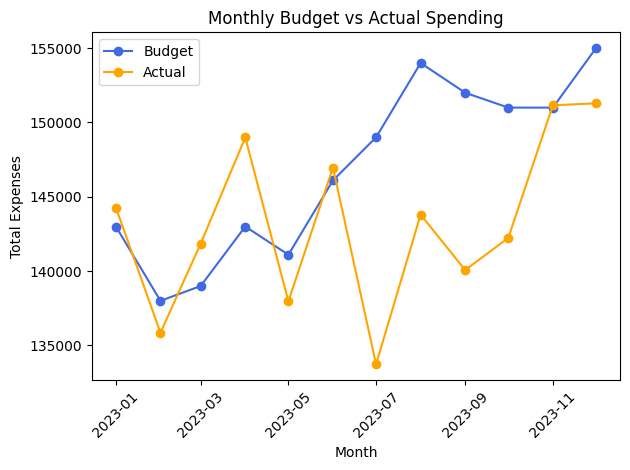

In [20]:
monthly_budget = budget.iloc[:, :-1].sum(axis=1)
monthly_actual = actual.iloc[:, :-1].sum(axis=1)

plt.plot(monthly_budget.index, monthly_budget, marker="o",
         color="royalblue", label="Budget")

plt.plot(monthly_actual.index, monthly_actual, marker="o",
                  color="orange", label="Actual")

plt.title("Monthly Budget vs Actual Spending")
plt.xlabel("Month")
plt.ylabel("Total Expenses")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
monthly_variance = monthly_actual - monthly_budget

print(monthly_variance.sort_values(ascending=False))

Month
2023-04-01     5990
2023-03-01     2853
2023-01-01     1270
2023-06-01      860
2023-11-01      154
2023-02-01    -2146
2023-05-01    -3132
2023-12-01    -3710
2023-10-01    -8762
2023-08-01   -10200
2023-09-01   -11930
2023-07-01   -15267
dtype: int64


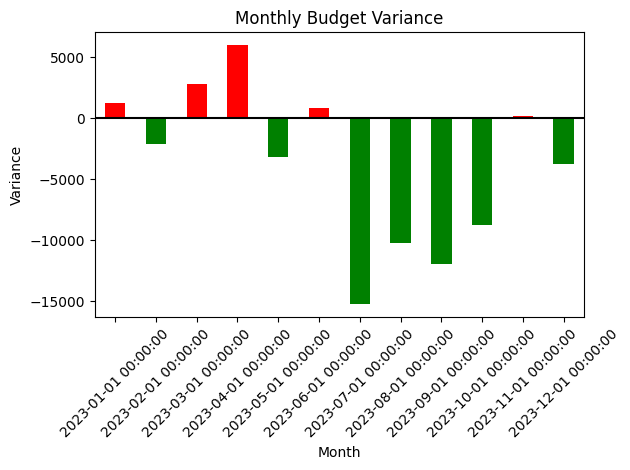

In [22]:
colors = ["red" if x > 0 else "green" for x in monthly_variance]

monthly_variance.sort_index().plot(kind="bar", color=colors)

plt.title("Monthly Budget Variance")
plt.xlabel("Month")
plt.ylabel("Variance")
plt.axhline(0, color="black")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [23]:
monthly_variance_pct = (monthly_variance / monthly_budget) * 100

print(monthly_variance_pct.round(2))

Month
2023-01-01     0.89
2023-02-01    -1.56
2023-03-01     2.05
2023-04-01     4.19
2023-05-01    -2.22
2023-06-01     0.59
2023-07-01   -10.25
2023-08-01    -6.62
2023-09-01    -7.85
2023-10-01    -5.80
2023-11-01     0.10
2023-12-01    -2.39
dtype: float64


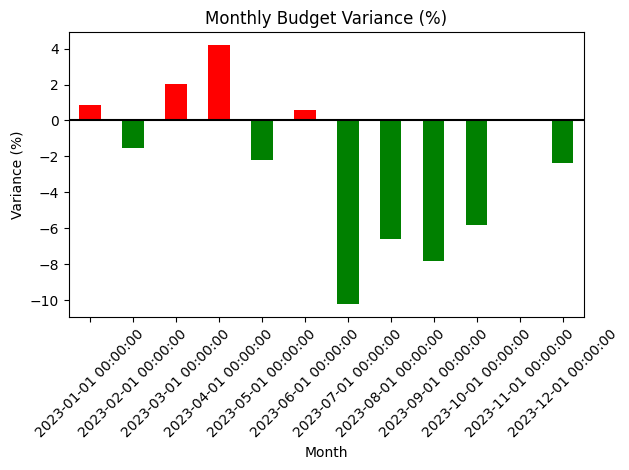

In [24]:
colors = ["red" if x > 0 else "green" for x in monthly_variance_pct]

monthly_variance_pct.plot(kind="bar", color=colors)

plt.title("Monthly Budget Variance (%)")
plt.ylabel("Variance (%)")
plt.axhline(0, color="black")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
summary = pd.DataFrame({
      "Budget": monthly_budget,
          "Actual": monthly_actual,
              "Variance": monthly_variance,
                  "Variance (%)": monthly_variance_pct
                  })

summary.round(2)


,Budget,Actual,Variance,Variance (%)
Month,,,,
2023-01-01,143000,144270,1270,0.89
2023-02-01,138000,135854,-2146,-1.56
2023-03-01,139000,141853,2853,2.05
2023-04-01,143000,148990,5990,4.19
2023-05-01,141100,137968,-3132,-2.22
2023-06-01,146100,146960,860,0.59
2023-07-01,149000,133733,-15267,-10.25
2023-08-01,154000,143800,-10200,-6.62
2023-09-01,152000,140070,-11930,-7.85


In [27]:
summary["Status"] = summary["Variance"].apply(
      lambda x: "Overspending" if x > 0 else "Under Budget" if x < 0 else "On Budget"
      )

print(summary[["Variance", "Variance (%)", "Status"]])


            Variance  Variance (%)        Status
Month                                           
2023-01-01      1270      0.888112  Overspending
2023-02-01     -2146     -1.555072  Under Budget
2023-03-01      2853      2.052518  Overspending
2023-04-01      5990      4.188811  Overspending
2023-05-01     -3132     -2.219702  Under Budget
2023-06-01       860      0.588638  Overspending
2023-07-01    -15267    -10.246309  Under Budget
2023-08-01    -10200     -6.623377  Under Budget
2023-09-01    -11930     -7.848684  Under Budget
2023-10-01     -8762     -5.802649  Under Budget
2023-11-01       154      0.101987  Overspending
2023-12-01     -3710     -2.393548  Under Budget


In [29]:
category_budget = budget.iloc[:, :-1].sum()
category_actual = actual.iloc[:, :-1].sum()

category_variance_pct = (
    (category_actual - category_budget) / category_budget
    ) * 100

print(category_variance_pct.round(2).sort_values(ascending=False))

Operatinal Costs      5.50
Maintenance Cost      5.18
Development Costs    -1.91
Marketing Costs      -7.10
Travelling Cost     -13.96
Training Cost       -20.93
dtype: float64


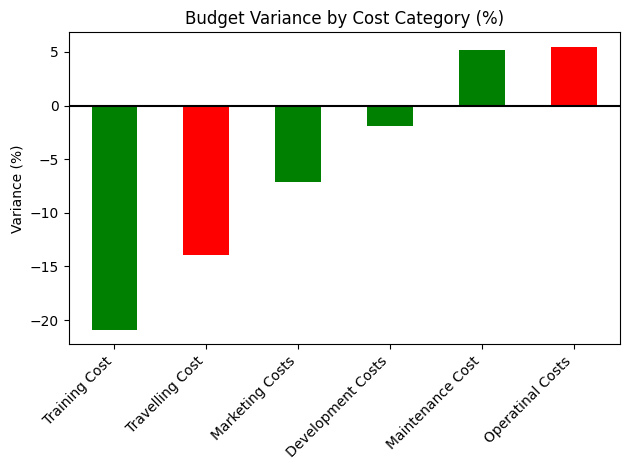

In [30]:
colors = ["red" if x > 0 else "green" for x in category_variance_pct]

category_variance_pct.sort_values().plot(kind="bar", color=colors)

plt.title("Budget Variance by Cost Category (%)")
plt.ylabel("Variance (%)")
plt.axhline(0, color="black")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()